# 06 · Run the RAG baseline and score it, in one notebook

The evaluation half of the baseline, in the same shape as `05_agent_and_scoring.ipynb`.

1. **Part A** is the baseline from `04_baseline_rag.ipynb`: parser, retriever, rubric, prompt, runner, and the free fake-model check.
2. **Part B** runs it on one split and writes `runs/baseline_{SPLIT}/`.
3. **Part C** scores it with **the same graders as `05`** — Track A, Track B, the deterministic checks, the LLM judge and Track C are copied from that notebook, not rewritten, so the baseline and the agent are measured the same way.

**To compare against the agent:** upload `runs_{SPLIT}.zip` from `02`/`05` when Part C asks. Then every table carries one row per condition — `rag` (this baseline), `single_pass` and `adaptive`. Press Cancel and you get the baseline alone.

The agent-only diagnostics (did the loop change a verdict, how loops ended, the human queue) stay in `05`; there is no loop here to diagnose.

Set `SPLIT = "dev"` while tuning and `"test"` once, for the final numbers.

## 0. Setup

Colab secrets (🔑 on the left, notebook access on): `OPENAI_API_KEY` (the course Portkey key) and `GH_TOKEN` (to clone the private repo for `contracts/`, `contracts.csv`, `rubric_v1.md`, `labels_gold.xlsx` and `cuad_gold_spans.csv`).

`pandas`, `scikit-learn` and `matplotlib` already come with Colab.

In [2]:
!pip -q install rank_bm25 openai

import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata, files
    if not Path("contract-review-agent").exists():
        token = userdata.get("GH_TOKEN")
        BRANCH = "main"
        !git clone -q -b {BRANCH} https://{token}@github.com/JJJJeny/contract-review-agent.git
    DATA_DIR = Path("contract-review-agent")
else:
    DATA_DIR = Path(".")          # run from the repo folder
print(sorted(p.name for p in DATA_DIR.iterdir()))

['.git', '.gitignore', '01_data_setup_v3.ipynb', '02_agent.ipynb', '02_agent_adk.ipynb', '03_scoring.ipynb', '04_baseline_rag.ipynb', '05_agent_and_scoring.ipynb', '06_baseline_and_scoring.ipynb', "Jenny's Labels.xlsx", "Kayla's Labels.xlsx", 'README.md', 'contracts', 'contracts.csv', 'contracts_pdf', 'cuad_gold_spans.csv', 'demo_agent', 'labels_gold.xlsx', 'results', 'rubric_v1.md']


## 1. Model (Portkey → GPT-5 nano)

`llm(system, user)` returns `(text, input_tokens, output_tokens)`. It retries twice on API errors.

In [3]:
import time
from openai import OpenAI

api_key = userdata.get("OPENAI_API_KEY") if IN_COLAB else os.environ.get("OPENAI_API_KEY")
MODEL = "@30875-fall26-openai/gpt-5-nano"
base_url = "https://api.portkey.ai/v1"
MODEL_PRICE_KEY = "gpt-5-nano"          # key into PRICES below
client = OpenAI(api_key=api_key, base_url=base_url) if api_key else None


def llm(system, user, tries=3):
    for attempt in range(tries):
        try:
            r = client.chat.completions.create(
                model=MODEL,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
            u = r.usage
            return (r.choices[0].message.content or ""), (u.prompt_tokens if u else 0), (u.completion_tokens if u else 0)
        except Exception as e:
            if attempt == tries - 1:
                raise
            print(f"API error ({str(e)[:120]}); retrying")
            time.sleep(2 ** (attempt + 1))

print("Model:", MODEL, "| key loaded:", bool(api_key))

Model: @30875-fall26-openai/gpt-5-nano | key loaded: True


## 2. Settings

Same values as the agent notebook's `BOUNDS` where they overlap.

In [4]:
FAMILIES = ["payment", "termination", "liability_indemnity",
            "confidentiality", "renewal", "dispute_governing_law"]

# USD per 1M tokens (input, output). Check current OpenAI pricing before reporting costs.
PRICES = {"gpt-5-nano": (0.05, 0.40), "gpt-4.1-nano": (0.10, 0.40), "fake": (0.0, 0.0)}

TOP_K = 4                  # chunks per family (agent: BOUNDS.prepass_top_k)
RETRIEVAL_MODE = "hybrid"  # "sparse" | "dense" | "hybrid"; agent pre-pass uses "hybrid"
CHUNK_WORDS, CHUNK_OVERLAP = 110, 30   # Contract.load defaults, same as the agent

## 3. Contract helpers (copied from the agent notebook)

Loads a contract, finds numbered headings, cuts it into chunks, and checks quotes (`contains`, `locate`).

In [5]:
import re
from dataclasses import dataclass, field
from pathlib import Path

# A numbered heading such as "9." "9.2" "12.1.3" at the start of a line or sentence,
# followed by a capital letter or "(" (so "30 days" or "Section 9.2" are not headings).
HEADING = re.compile(r'(?:(?<=\n)|(?<=^)|(?<=\. )|(?<=: ))[ \t]*(\d{1,2}(?:\.\d{1,2}){0,3})\.?[ \t]+(?=[A-Z(“"])')
ATTACHMENT = re.compile(r'\b(EXHIBIT|SCHEDULE|APPENDIX|ANNEX|Exhibit|Schedule|Appendix|Annex)\s+["“]?([A-Z0-9]{1,2})\b["”]?')
CROSS_REF = re.compile(
    r'(?:\b(?:Section|Sections|Paragraph|Clause|Article)\s+\d{1,2}(?:\.\d{1,2})*(?:\s*\([a-z0-9]{1,4}\))*'
    r'|§\s*\d{1,2}(?:\.\d{1,2})*'
    r'|\b(?:Exhibit|Schedule|Appendix|Annex|EXHIBIT|SCHEDULE)\s+["“]?[A-Z0-9]{1,2}\b["”]?'
    r'|\bnotwithstanding\b|\bexcept as (?:set forth|provided|otherwise)|\bsubject to (?:Section|Article|Paragraph|Clause|Exhibit|Schedule)\b)',
    re.I)
DEFINED = re.compile(r'[("“]\s*(?:the\s+)?["“]([A-Z][A-Za-z0-9\-]*(?:\s+[A-Z][A-Za-z0-9\-]*){0,4})["”]')
MEANS = re.compile(r'\b([A-Z][A-Za-z\-]*(?:\s+[A-Z][A-Za-z\-]*){0,4})["”]?\s+(?:shall\s+)?(?:means?|has the meaning)\b')
ROLE_TERMS = {"Customer", "Provider", "Recipient", "Service", "Services", "Company", "Contractor", "Client", "Vendor"}
TRIVIAL_TERMS = {"Agreement", "Party", "Parties", "Effective Date", "Section", "Exhibit", "Schedule"}


def norm(s) -> str:
    s = s or ""
    return re.sub(r"\s+", " ", s.replace("“", '"').replace("”", '"').replace("’", "'")).strip()


@dataclass
class Chunk:
    idx: int
    start: int
    end: int
    section: str
    text: str


@dataclass
class Contract:
    cid: str
    text: str
    meta: dict = field(default_factory=dict)
    headings: list = field(default_factory=list)   # [(pos, "9.2")]
    chunks: list = field(default_factory=list)
    defined_terms: dict = field(default_factory=dict)  # term -> definition sentence
    preamble_terms: set = field(default_factory=set)

    @classmethod
    def load(cls, path, meta=None, chunk_words=110, overlap=30):
        text = Path(path).read_text(encoding="utf-8", errors="replace")
        c = cls(cid=Path(path).stem, text=text, meta=meta or {})
        c.headings = [(m.start(1), m.group(1)) for m in HEADING.finditer(text)]
        c._chunk(chunk_words, overlap)
        c._index_terms()
        return c

    def section_at(self, pos: int) -> str:
        sec = ""
        for p, s in self.headings:
            if p > pos:
                break
            sec = s
        return f"§{sec}" if sec else "untitled"

    def _chunk(self, size, overlap):
        words = [(m.start(), m.end()) for m in re.finditer(r"\S+", self.text)]
        step = size - overlap
        for i in range(0, max(1, len(words)), step):
            span = words[i:i + size]
            if not span:
                break
            s, e = span[0][0], span[-1][1]
            self.chunks.append(Chunk(len(self.chunks), s, e, self.section_at(s), norm(self.text[s:e])))
            if i + size >= len(words):
                break

    def _sentence_around(self, pos: int, max_chars=600) -> str:
        left = max(self.text.rfind(". ", 0, pos), self.text.rfind("\n\n", 0, pos))
        right = self.text.find(". ", pos)
        right = len(self.text) if right == -1 else right + 1
        return norm(self.text[left + 1:right])[:max_chars]

    def _index_terms(self):
        for rx in (DEFINED, MEANS):
            for m in rx.finditer(self.text):
                term = m.group(1).strip()
                if term in TRIVIAL_TERMS or len(term) < 3 or term in self.defined_terms:
                    continue
                self.defined_terms[term] = self._sentence_around(m.start())
                if m.start() < 1500:          # parties and roles are introduced in the preamble
                    self.preamble_terms.add(term)

    def contains(self, quote: str) -> bool:
        """verify_quote: does this exact text (whitespace-normalised) appear in the contract?"""
        q = norm(quote or "").strip(' ."')
        return bool(q) and q.lower() in norm(self.text).lower()

    def locate(self, quote: str):
        """Character span [start, end) of a quote in the original text (whitespace-insensitive), or None."""
        q = norm(quote).strip(' ."')
        if not q:
            return None
        if not hasattr(self, "_flat"):
            # normalised copy of the text plus a map from each normalised character to its original position
            flat, pos, prev_space = [], [], False
            for i, ch in enumerate(self.text.replace("“", '"').replace("”", '"').replace("’", "'")):
                if ch.isspace():
                    if not prev_space and flat:
                        flat.append(" ")
                        pos.append(i)
                    prev_space = True
                else:
                    flat.append(ch)
                    pos.append(i)
                    prev_space = False
            self._flat, self._pos = "".join(flat).lower(), pos
        k = self._flat.find(q.lower())
        if k < 0:
            return None
        return [self._pos[k], self._pos[k + len(q) - 1] + 1]

    def section_text(self, section_id: str, max_words=350) -> dict:
        sid = section_id.strip()
        att = ATTACHMENT.search(sid)
        if att or re.match(r'(?i)(exhibit|schedule|appendix|annex)', sid):
            return self._attachment_text(sid, max_words)
        num = re.search(r'\d{1,2}(?:\.\d{1,2})*', sid)
        if not num:
            return {"found": False, "note": f"could not parse section id {section_id!r}"}
        num = num.group(0)
        hits = [i for i, (p, s) in enumerate(self.headings) if s == num]
        if not hits:
            return {"found": False, "section": num,
                    "note": "no heading with this number; the reference may be wrong or the section may be in a missing exhibit"}
        i = hits[0]
        start = self.headings[i][0]
        depth = num.count(".")
        end = len(self.text)
        for p, s in self.headings[i + 1:]:
            if s.count(".") <= depth:
                end = p
                break
        words = norm(self.text[start:end]).split()
        return {"found": True, "section": f"§{num}", "text": " ".join(words[:max_words]),
                "truncated": len(words) > max_words}

    def _attachment_text(self, sid, max_words):
        m = re.search(r'(?i)(exhibit|schedule|appendix|annex)\s+["“]?([A-Z0-9]{1,2})', sid)
        if not m:
            return {"found": False, "note": f"could not parse attachment id {sid!r}"}
        kind, label = m.group(1).lower(), m.group(2).upper()
        rx = re.compile(rf'(?i)\b{kind}\s+["“]?{re.escape(label)}\b["”]?')
        mentions, body_starts = [], []
        for h in rx.finditer(self.text):
            before = self.text[max(0, h.start() - 40):h.start()]
            ctx = norm(self.text[max(0, h.start() - 80):h.end() + 80])
            mentions.append(ctx)
            # Treat it as the attachment itself when written as a heading (upper case, or on its own line).
            after = self.text[h.end():h.end() + 3]
            is_heading = self.text[h.start():h.end()].isupper() or before.rstrip(" \t").endswith("\n")
            # Attachments are filed after the body, so ignore table-of-contents lines ("Schedule A: Fees").
            past_body = not self.headings or h.start() > self.headings[-1][0]
            if (is_heading and past_body and not after.lstrip().startswith(":")
                    and not re.search(r'(?i)(in|to|on|of|per|under|the|see)\s*$', before)):
                body_starts.append(h.start())
        if body_starts:
            start = body_starts[-1]
            words = norm(self.text[start:]).split()
            return {"found": True, "section": f"{kind.title()} {label}", "text": " ".join(words[:max_words]),
                    "truncated": len(words) > max_words}
        return {"found": False, "section": f"{kind.title()} {label}",
                "note": "EXHIBIT NOT INCLUDED: only references to it appear in the filed text",
                "mentions": mentions[:3]}

    def define(self, term: str) -> dict:
        t = term.strip(' "“”')
        for k, v in self.defined_terms.items():
            if k.lower() == t.lower():
                return {"found": True, "term": k, "definition": v}
        # fallback: first sentence where the term appears in quotes or followed by "means"
        m = re.search(rf'["“]{re.escape(t)}["”]|{re.escape(t)}\s+(?:shall\s+)?means', self.text, re.I)
        if m:
            return {"found": True, "term": t, "definition": self._sentence_around(m.start())}
        return {"found": False, "term": t, "note": "no definition found; the term may be defined in a missing exhibit"}


def cross_refs(text: str) -> list:
    return sorted({norm(m.group(0)) for m in CROSS_REF.finditer(text)})


def undefined_terms(text: str, contract: Contract, already_resolved=()) -> list:
    """Defined terms used in a span whose definition is not yet part of the evidence."""
    out = []
    for term in contract.defined_terms:
        if term in already_resolved:
            continue
        if term in contract.preamble_terms or term in ROLE_TERMS:
            continue
        if re.search(rf'\b{re.escape(term)}\b', text):
            out.append(term)
    return out

## 4. Retriever (agent's version + stem fix)

Identical to the agent notebook except `_expand`: a query word that never appears in the contract (e.g. the stem `terminat`) is replaced by the contract's words that start with it (`terminate`, `terminated`, `termination`). `02_agent_adk.ipynb` carries the same cell, so the baseline and the agent retrieve identically.

In [6]:
import re
import numpy as np
from rank_bm25 import BM25Okapi

TOKEN = re.compile(r"[a-z0-9]+")


def tok(s):
    return TOKEN.findall(s.lower())


class Retriever:
    def __init__(self, contract, embedder=None):
        self.c = contract
        docs = [tok(ch.text) for ch in contract.chunks]
        self.bm25 = BM25Okapi(docs)
        self.vocab = {t for d in docs for t in d}
        self.embedder = embedder          # callable(list[str]) -> np.ndarray, or None
        self._vecs = None

    def _expand(self, query):
        """Stem fix: BM25 matches whole words, so a stem like "terminat" matched nothing.
        Replace each query word that is not in the contract by the contract words that start with it."""
        out = []
        for t in tok(query):
            if t in self.vocab or len(t) < 4:
                out.append(t)
            else:
                out += sorted(v for v in self.vocab if v.startswith(t)) or [t]
        return out

    def _dense_scores(self, query):
        if self._vecs is None:
            self._vecs = self.embedder([ch.text for ch in self.c.chunks])
        q = self.embedder([query])[0]
        return self._vecs @ q / (np.linalg.norm(self._vecs, axis=1) * np.linalg.norm(q) + 1e-9)

    def search(self, query, mode="hybrid", k=3, exclude=()):
        """Return the top-k chunks as dicts. mode: sparse | dense | hybrid."""
        if mode in ("dense", "hybrid") and self.embedder is None:
            mode = "sparse"               # no embeddings available: degrade, and say so in the result
        sparse = self.bm25.get_scores(self._expand(query))
        if mode == "sparse":
            score = sparse
        else:
            dense = self._dense_scores(query)
            if mode == "dense":
                score = dense
            else:
                rank = lambda a: np.argsort(np.argsort(-a))
                score = 1 / (60 + rank(sparse)) + 1 / (60 + rank(dense))
        order = [i for i in np.argsort(-score) if i not in exclude][:k]
        return mode, [{"chunk": int(i), "section": self.c.chunks[i].section,
                       "text": self.c.chunks[i].text} for i in order]

## 5. Embeddings for hybrid retrieval (copied from the agent notebook)

If the course key does not allow embeddings, this prints `dense retrieval off` and retrieval falls back to BM25.

In [7]:
from openai import OpenAI

EMBED_MODEL = "@30875-fall26-openai/text-embedding-3-small"


def make_embedder():
    client = OpenAI(api_key=api_key, base_url=base_url)

    def embed(texts):
        out = []
        for i in range(0, len(texts), 100):
            r = client.embeddings.create(model=EMBED_MODEL, input=texts[i:i + 100])
            out += [d.embedding for d in r.data]
        return np.array(out, dtype=np.float32)

    try:
        embed(["test"])
        return embed
    except Exception as e:            # the course key may not allow embeddings: search falls back to sparse
        print("dense retrieval off:", str(e)[:200])
        return None


EMBEDDER = make_embedder() if client else None
print("dense retrieval:", "on" if EMBEDDER else "off")

dense retrieval: on


## 6. Rubric (copied from the agent notebook)

Parses `rubric_v1.md`: each family's section, its **Keywords** line, and each sub-criterion row.

In [8]:
import re
from pathlib import Path


def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


class Rubric:
    def __init__(self, path):
        self.text = Path(path).read_text(encoding="utf-8")
        self.rules = {}           # rule_id -> text
        self.family_keywords = {}
        self._parse()

    def _parse(self):
        parts = re.split(r"^(#{2,3} .+)$", self.text, flags=re.M)
        for head, body in zip(parts[1::2], parts[2::2]):
            m = re.match(r"#{2,3} (\d+(?:\.\d+)?)\.? (.+)", head)
            if not m:
                continue
            num, title = m.group(1), m.group(2).strip()
            self.rules[num] = f"{head}\n{body.strip()}"
            fam = title.split()[0]
            if re.fullmatch(r"[a-z_]+", fam):              # "## 1. payment" etc.
                self.rules[fam] = self.rules[num]
                kw = re.search(r"\*\*Keywords:\*\* (.+)", body)
                if kw:
                    self.family_keywords[fam] = kw.group(1).rstrip(".")
                for row in re.findall(r"^\| ([^|]+?) \| (.+)$", body, flags=re.M):
                    name = row[0].strip()
                    if name.startswith("Sub-criterion") or set(name) <= set("-"):
                        continue
                    self.rules[f"{fam}.{slug(name)}"] = f"| {name} | {row[1]}"
                for label in ("Missing", "Severity", "Absence rule", "Customer is not the payer"):
                    p = re.search(rf"^\*\*{label}[^*]*\*\*.*$", body, flags=re.M)
                    if p:
                        self.rules[f"{fam}.{slug(label)}"] = p.group(0)

    def family_rules(self, family):
        return self.rules.get(family, "")

    def general_rules(self):
        return "\n\n".join(self.rules[k] for k in ("0.2", "0.3", "0.4") if k in self.rules)

    def lookup(self, rule_id):
        rid = rule_id.strip().lstrip("§").lower()
        if rid in self.rules:
            return {"found": True, "rule_id": rid, "text": self.rules[rid]}
        near = [k for k in self.rules if rid.split(".")[0] in k][:12]
        return {"found": False, "rule_id": rid, "available": near or sorted(self.rules)[:20]}


RUBRIC = Rubric(DATA_DIR / "rubric_v1.md")
print(len(RUBRIC.rules), "rules")

67 rules


## 7. Token accounting and JSON parsing (copied from the agent notebook)

In [9]:
import json
import re
import time

import numpy as np



class Usage:
    def __init__(self, model):
        self.model = model
        self.input_tokens = self.output_tokens = self.calls = 0

    def add(self, i, o):
        self.input_tokens += i
        self.output_tokens += o
        self.calls += 1
        return self.cost_of(i, o)

    def cost_of(self, i, o):
        pin, pout = PRICES.get(self.model, (0.0, 0.0))
        return (i * pin + o * pout) / 1e6

    @property
    def tokens(self):
        return self.input_tokens + self.output_tokens

    @property
    def cost(self):
        return self.cost_of(self.input_tokens, self.output_tokens)


def parse_json(text):
    """Parse a model reply that should be JSON. Never raises.

    Small models sometimes wrap the JSON in prose or send several objects back to back
    ("Extra data" errors). Every object in the text is decoded; "families" / "items" are
    merged across objects, otherwise the largest object wins.
    """
    text = text or ""
    dec, objs, i = json.JSONDecoder(), [], 0
    while True:
        i = text.find("{", i)
        if i < 0:
            break
        try:
            obj, i = dec.raw_decode(text, i)
            if isinstance(obj, dict):
                objs.append(obj)
        except json.JSONDecodeError:
            i += 1
    if not objs:
        print("warning: no JSON in model reply:", text[:200].replace("\n", " "))
        return {}
    for key in ("families", "items"):
        if any(key in o for o in objs):
            merged = {} if key == "families" else []
            for o in objs:
                part = o.get(key)
                if isinstance(merged, dict) and isinstance(part, dict):
                    merged.update(part)
                elif isinstance(merged, list) and isinstance(part, list):
                    merged += part
            return {key: merged}
    return max(objs, key=lambda o: len(json.dumps(o, default=str)))

## 8. Prompt

`RAG_SYSTEM` is the agent notebook's prompt plus two additions: the rubric's **general rules** (§0.2–0.4 — what each verdict means, the severity table, and the rule that `unclear` caps at medium) and a `recommendation` field.

Both additions are about fairness, not capability. Without §0.2–0.4 the baseline would be picking verdicts whose definitions it was never given while the agent's pre-pass has them, and the proposal scores "usefulness of recommendations" (§8), which needs the baseline to produce one at all.

**Add the same `{general}` block to `RAG_SYSTEM` in `02_agent_adk.ipynb` §7.**

In [10]:
PERSPECTIVE = (
    "You review vendor service agreements for a SMALL-BUSINESS CUSTOMER that buys maintenance or "
    "services. It has no lawyer and little bargaining power. Judge every clause from the customer's "
    "side, even when the provider filed the contract. Apply the rubric exactly; do not invent thresholds."
)

RAG_SYSTEM = PERSPECTIVE + """

Baseline: read the retrieved passages for ONE clause family and judge it with the rubric below.

Rules that apply to every family:
{general}

Rules for this family:
{rules}

Return JSON only:
{{"verdict": "acceptable|risky|missing|unclear",
  "severity": "high|medium|low|n/a",
  "evidence_text": "exact sentence copied from a passage (empty if the clause is missing)",
  "section_ref": "the section as printed, e.g. 9.2; copy the section tag of the passage you quoted",
  "evidence_2": "second exact quote the verdict depends on, or empty",
  "section_ref_2": "",
  "recommendation": "one plain sentence the customer can say to the provider; empty if acceptable",
  "notes": "which sub-criterion decided it"}}"""

print(RAG_SYSTEM.format(general=RUBRIC.general_rules(), rules=RUBRIC.family_rules("renewal"))[:1800])

You review vendor service agreements for a SMALL-BUSINESS CUSTOMER that buys maintenance or services. It has no lawyer and little bargaining power. Judge every clause from the customer's side, even when the provider filed the contract. Apply the rubric exactly; do not invent thresholds.

Baseline: read the retrieved passages for ONE clause family and judge it with the rubric below.

Rules that apply to every family:
### 0.2 One row = one family
Each contract gets exactly one verdict per family (6 rows). If a family has several clauses (e.g. termination for convenience *and* for cause), judge each sub-criterion, then the row verdict is the **worst** sub-result (risky > unclear > missing > acceptable), with one exception: see 0.4.

### 0.3 Verdicts
| Verdict | Use when |
|---|---|
| **acceptable** | The clause exists and meets every "acceptable" criterion for that family, or it is absent *and* its absence helps the customer (e.g. no auto-renewal). |
| **risky** | The clause exists and at

## 9. The baseline

`review_family` = retrieve → one call → parse. `review_contract` runs the six families. After the call, **code** (not the model):

- enforces rubric §0.4 on severity (`clean_severity`): `acceptable` → `n/a`, a flagged row always carries a severity, and `unclear` is capped at **medium**. The baseline cannot know whether "both readings are high", so it applies the cap and records in `notes` that it did;
- fills `section_ref` from where the quote sits in the contract when the model left it blank (`section_for`);
- for a `missing` verdict, writes the keywords searched and the sections seen into `notes`. Rubric §0.5 requires this: a "missing" with no search record is treated as "not checked" during adjudication;
- checks each quote word for word against the contract (`evidence_verified`);
- records the character span of each quote (`evidence_spans`, for Track A overlap with CUAD).

The quote check only **records** whether a quote is real. Acting on a failed check is the agent's job, not the baseline's.

In [11]:
VERDICTS = {"acceptable", "risky", "missing", "unclear"}
SEVERITIES = {"high", "medium", "low", "n/a"}


def clean_severity(verdict, severity):
    """Rubric §0.4, enforced in code. Returns (severity, note) so any change is auditable."""
    s = (severity or "").strip().lower()
    if verdict == "acceptable":
        return "n/a", ""
    if s not in SEVERITIES or s == "n/a":
        return "low", f" [severity {severity!r} not usable for a {verdict} row; set to low]"
    if verdict == "unclear" and s == "high":
        return "medium", " [§0.4: unclear capped at medium]"
    return s, ""


def section_for(contract, quote, given):
    """Keep the model's section ref if it gave one, otherwise read it off where the quote sits."""
    if (given or "").strip():
        return given.strip()
    sp = contract.locate(quote or "")
    return contract.section_at(sp[0]) if sp else ""


def review_family(contract, retriever, fam, llm, usage):
    query = RUBRIC.family_keywords.get(fam, fam)
    mode_used, hits = retriever.search(query, RETRIEVAL_MODE, TOP_K)
    user = json.dumps({"family": fam, "passages": hits}, ensure_ascii=False)
    text, i, o = llm(RAG_SYSTEM.format(general=RUBRIC.general_rules(), rules=RUBRIC.family_rules(fam)), user)
    usage.add(i, o)
    d = parse_json(text)
    notes = (d.get("notes") or "").strip()

    if d.get("verdict") not in VERDICTS:
        notes += f" [unparseable verdict {d.get('verdict')!r}; set to unclear]"
        d["verdict"] = "unclear"
    d["severity"], sev_note = clean_severity(d["verdict"], d.get("severity"))
    notes += sev_note

    for q_key, s_key in (("evidence_text", "section_ref"), ("evidence_2", "section_ref_2")):
        d[s_key] = section_for(contract, d.get(q_key), d.get(s_key))
        q = d.get(q_key) or ""
        d[q_key + "_verified"] = q in ("", "NONE FOUND") or contract.contains(q)

    if d["verdict"] == "missing":          # rubric §0.5: a missing verdict must show its search
        notes += f" [searched: {query}; sections seen: {', '.join(h['section'] for h in hits)}]"

    d["notes"] = notes.strip()
    d["recommendation"] = (d.get("recommendation") or "").strip()
    d["evidence_spans"] = [sp for sp in (contract.locate(d.get("evidence_text") or ""),
                                         contract.locate(d.get("evidence_2") or "")) if sp]
    return d, {"contract_id": contract.cid, "family": fam, "query": query,
               "mode_used": mode_used, "passages": hits, "raw_reply": text[:2000]}


def review_contract(contract, llm, embedder=None):
    retriever = Retriever(contract, embedder)
    usage = Usage(getattr(llm, "price_key", MODEL_PRICE_KEY))
    t0 = time.time()
    results, retrieved = {}, []
    for fam in FAMILIES:
        results[fam], r = review_family(contract, retriever, fam, llm, usage)
        retrieved.append(r)
    summary = {"contract_id": contract.cid, "llm_calls": usage.calls, "tokens": usage.tokens,
               "cost_usd": round(usage.cost, 5), "elapsed_s": round(time.time() - t0, 2),
               "retrieval_mode_used": sorted({r["mode_used"] for r in retrieved})}
    return results, retrieved, summary

## 10. Runner

Writes the agent's 21 `results.csv` columns in the same order, plus `recommendation` as a 22nd — the baseline's counterpart to the agent's `ask` / `fallback`, which live in its `revision_plans.json`. Scoring merges on `contract_id` + `family`, so the extra trailing column changes nothing.

Agent-only columns are filled with their "no loop" values: `path = rag`, `steps = 0`, `verdict_changed = False`, and blanks for confidence, pre-pass and triggers.

In [12]:
import csv

COLUMNS = ["contract_id", "short_name", "split", "family", "verdict", "severity", "evidence_text",
           "section_ref", "evidence_2", "section_ref_2", "notes",
           "confidence", "path", "steps", "evidence_verified",
           "prepass_verdict", "prepass_severity", "prepass_confidence", "verdict_changed", "triggers_fired",
           "evidence_spans", "recommendation"]


def load_meta():
    with open(DATA_DIR / "contracts.csv", newline="") as f:
        return {r["contract_id"]: r for r in csv.DictReader(f)}


def run_baseline(ids, llm=llm, out_dir="runs/baseline_dev", embedder=None, allow_test=False):
    meta = load_meta()
    test_ids = [i for i in ids if meta[i]["split"] == "test"]
    if test_ids and not allow_test:
        raise ValueError(f"{test_ids} are test contracts. Tune on dev only; pass allow_test=True for the final scoring run.")
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    rows, retrieved, summary = [], [], []
    for cid in ids:
        contract = Contract.load(DATA_DIR / "contracts" / f"{cid}.txt", meta[cid], CHUNK_WORDS, CHUNK_OVERLAP)
        res, ret, s = review_contract(contract, llm, embedder)
        for fam in FAMILIES:
            f = res[fam]
            rows.append({"contract_id": cid, "short_name": meta[cid]["short_name"], "split": meta[cid]["split"],
                         "family": fam, **{k: f.get(k, "") for k in COLUMNS[4:11]},
                         "confidence": "", "path": "rag", "steps": 0,
                         "evidence_verified": f["evidence_text_verified"] and f["evidence_2_verified"],
                         "prepass_verdict": "", "prepass_severity": "", "prepass_confidence": "",
                         "verdict_changed": False, "triggers_fired": "",
                         "evidence_spans": json.dumps(f["evidence_spans"]),
                         "recommendation": f.get("recommendation", "")})
        retrieved += ret
        summary.append(s)
        print(s)
    with open(out_dir / "results.csv", "w", newline="") as f:
        w = csv.DictWriter(f, COLUMNS)
        w.writeheader()
        w.writerows(rows)
    with open(out_dir / "retrieved.jsonl", "w") as f:
        for r in retrieved:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    (out_dir / "summary.json").write_text(json.dumps(
        {"model": getattr(llm, "price_key", MODEL), "condition": "rag", "retrieval_mode": RETRIEVAL_MODE,
         "top_k": TOP_K, "chunk_words": CHUNK_WORDS, "chunk_overlap": CHUNK_OVERLAP,
         "contracts": summary}, indent=2))
    print("wrote", out_dir)
    return out_dir

## 11. Free check with a fake model

No API calls. Checks retrieval, the stem fix, parsing, the §0.4 severity rules, the `section_ref` backfill, the search record on a `missing` verdict, the output columns and the dev-only guard. Run it after any change.

In [13]:
import re


def fake_llm(system, user):
    """Quotes the first sentence of the first passage and calls it risky. Costs nothing.
    Leaves section_ref blank on purpose, so the backfill is exercised."""
    ps = json.loads(user)["passages"]
    q = re.split(r"(?<=[.;])\s", ps[0]["text"])[0][:300] if ps else ""
    return json.dumps({"verdict": "risky", "severity": "medium", "evidence_text": q, "section_ref": "",
                       "recommendation": "Ask for a fairer term.", "notes": "fake"}), 1000, 100
fake_llm.price_key = "fake"


def fake_missing_llm(system, user):
    """Always answers "missing", to check the rubric §0.5 search record."""
    return json.dumps({"verdict": "missing", "severity": "high", "evidence_text": "",
                       "notes": "nothing found"}), 500, 50
fake_missing_llm.price_key = "fake"

DEV = ["C01", "C02", "C11", "C12"]

# the stem fix: "terminat" must now reach termination clauses
c01 = Contract.load(DATA_DIR / "contracts" / "C01.txt")
r01 = Retriever(c01)
assert "terminat" not in r01.vocab and any(t.startswith("terminat") for t in r01._expand("terminat"))
assert any(t.startswith("indemnif") for t in r01._expand("indemnif"))

# rubric §0.4, enforced in code
assert clean_severity("acceptable", "high") == ("n/a", "")
assert clean_severity("unclear", "high")[0] == "medium"
assert clean_severity("risky", "n/a")[0] == "low"
assert clean_severity("risky", "nonsense")[0] == "low"
assert clean_severity("risky", "HIGH ") == ("high", "")

d = run_baseline(DEV, fake_llm, "runs/check_baseline")
rows = list(csv.DictReader(open(d / "results.csv")))
assert len(rows) == len(DEV) * 6 and list(rows[0]) == COLUMNS
assert all(r["path"] == "rag" for r in rows)
assert sum(r["evidence_verified"] == "True" for r in rows) >= len(rows) * 0.8, "fake quotes come from passages, so most must verify"
assert all(r["section_ref"] for r in rows), "section_ref must be filled by the model or backfilled from the quote"
assert all(r["recommendation"] for r in rows), "a flagged row needs a recommendation"

# a "missing" verdict must record what was searched (rubric §0.5)
d2 = run_baseline(["C01"], fake_missing_llm, "runs/check_missing")
rows2 = list(csv.DictReader(open(d2 / "results.csv")))
assert all("searched:" in r["notes"] for r in rows2)
assert all(r["severity"] == "high" for r in rows2), "missing keeps its severity; only unclear is capped"

try:
    run_baseline(["C03"], fake_llm, "runs/check_guard")
    raise AssertionError("test contract was not refused")
except ValueError:
    pass
print("all checks passed")

{'contract_id': 'C01', 'llm_calls': 6, 'tokens': 6600, 'cost_usd': 0.0, 'elapsed_s': 0.02, 'retrieval_mode_used': ['sparse']}
{'contract_id': 'C02', 'llm_calls': 6, 'tokens': 6600, 'cost_usd': 0.0, 'elapsed_s': 0.02, 'retrieval_mode_used': ['sparse']}
{'contract_id': 'C11', 'llm_calls': 6, 'tokens': 6600, 'cost_usd': 0.0, 'elapsed_s': 0.02, 'retrieval_mode_used': ['sparse']}
{'contract_id': 'C12', 'llm_calls': 6, 'tokens': 6600, 'cost_usd': 0.0, 'elapsed_s': 0.02, 'retrieval_mode_used': ['sparse']}
wrote runs/check_baseline
{'contract_id': 'C01', 'llm_calls': 6, 'tokens': 3300, 'cost_usd': 0.0, 'elapsed_s': 0.01, 'retrieval_mode_used': ['sparse']}
wrote runs/check_missing
all checks passed


# Part B · Run the baseline

## 12. Run on one split

`"dev"` while tuning, `"test"` once for the final numbers. The run goes to `runs/baseline_{SPLIT}`, which is the folder Part C and `05` both look for. A finished folder is skipped, so a rerun after an error costs nothing.

Start with one contract to check the connection and the cost.

In [14]:
out_dir = run_baseline(["C01"], llm, "runs/baseline_C01", embedder=EMBEDDER)

{'contract_id': 'C01', 'llm_calls': 6, 'tokens': 37872, 'cost_usd': 0.01152, 'elapsed_s': 226.91, 'retrieval_mode_used': ['hybrid']}
wrote runs/baseline_C01


In [16]:
SPLIT = "dev"                              # "test" for the final numbers
IDS = sorted(cid for cid, m in load_meta().items() if m["split"] == SPLIT)
out_dir = Path(f"runs/baseline_{SPLIT}")

if (out_dir / "results.csv").exists():
    print("skip (delete the folder to rerun):", out_dir)
else:
    run_baseline(IDS, llm, str(out_dir), embedder=EMBEDDER, allow_test=SPLIT == "test")

{'contract_id': 'C01', 'llm_calls': 6, 'tokens': 32284, 'cost_usd': 0.00929, 'elapsed_s': 259.42, 'retrieval_mode_used': ['hybrid']}
{'contract_id': 'C02', 'llm_calls': 6, 'tokens': 48428, 'cost_usd': 0.01576, 'elapsed_s': 229.69, 'retrieval_mode_used': ['hybrid']}
{'contract_id': 'C11', 'llm_calls': 6, 'tokens': 44415, 'cost_usd': 0.0141, 'elapsed_s': 220.57, 'retrieval_mode_used': ['hybrid']}
{'contract_id': 'C12', 'llm_calls': 6, 'tokens': 47135, 'cost_usd': 0.01518, 'elapsed_s': 228.35, 'retrieval_mode_used': ['hybrid']}
wrote runs/baseline_dev


## 13. Quick look

In [17]:
import pandas as pd

res = pd.read_csv(out_dir / "results.csv")
summ = pd.DataFrame(json.load(open(out_dir / "summary.json"))["contracts"])
print(f"calls {summ.llm_calls.sum()}  tokens {summ.tokens.sum()}  cost ${summ.cost_usd.sum():.4f}  "
      f"time {summ.elapsed_s.sum():.0f}s  retrieval {sorted(set(sum(summ.retrieval_mode_used, [])))}")
print(f"quotes verified {res.evidence_verified.mean():.0%}  |  "
      f"section refs filled {(res.section_ref.fillna('') != '').mean():.0%}  |  "
      f"rows with a recommendation {(res.recommendation.fillna('') != '').mean():.0%}  |  "
      f"unparseable replies {int(res.notes.fillna('').str.contains('unparseable').sum())}")
display(pd.crosstab(res.family, res.verdict, margins=True))
res[["contract_id", "family", "verdict", "severity", "section_ref", "evidence_verified", "recommendation"]]

calls 24  tokens 172262  cost $0.0543  time 938s  retrieval ['hybrid']
quotes verified 92%  |  section refs filled 96%  |  rows with a recommendation 100%  |  unparseable replies 0


verdict,missing,risky,unclear,All
family,,,,
confidentiality,2,2,0,4
dispute_governing_law,0,4,0,4
liability_indemnity,2,2,0,4
payment,2,2,0,4
renewal,2,2,0,4
termination,1,2,1,4
All,9,14,1,24


,contract_id,family,verdict,severity,section_ref,evidence_verified,recommendation
0,C01,payment,missing,medium,NaN,True,"Add clear payment terms (e.g., net 30 from rec..."
1,C01,termination,missing,high,§16,True,Add a mutual termination-for-cause clause (for...
2,C01,liability_indemnity,risky,high,§15,True,Remove or narrow the carve-out so that liabili...
3,C01,confidentiality,risky,medium,§14,True,Add explicit post-termination return/destroy o...
4,C01,renewal,risky,high,§16,True,Institute a fixed term with renewal only by mu...
5,C01,dispute_governing_law,risky,medium,§20,True,Please revise governing law to be in our state...
6,C02,payment,risky,medium,§5,True,RequestNet 30 days from receipt of a correct i...
7,C02,termination,risky,high,§4,True,Cap termination charges to fees for services d...
8,C02,liability_indemnity,missing,medium,§6,True,Push to add a defined provider cap of at least...
9,C02,confidentiality,missing,high,§12,True,Add mutual confidentiality language that survi...


# Part C · Scoring

## 14. Load the runs

The baseline you just ran is picked up from `runs/baseline_{SPLIT}`. To put the agent beside it, upload `runs_{SPLIT}.zip` from `02`/`05` when prompted; Cancel scores the baseline alone.

Anything not found is listed and skipped, so every table below shows only the conditions that are actually present.

In [18]:
import zipfile
import pandas as pd
from sklearn.metrics import cohen_kappa_score

if IN_COLAB:
    for name in files.upload():            # baseline_run.zip from 04 (optional)
        zipfile.ZipFile(name).extractall(".")

CONDITIONS = ["rag", "single_pass", "adaptive"]  # baseline -> loop off -> full agent
OUT = Path("scores"); OUT.mkdir(exist_ok=True)


def find_run(cond):
    names = [f"{SPLIT}_{cond}"] + ([f"baseline_{SPLIT}"] if cond == "rag" else [])   # 04 writes runs/baseline_{split}
    for root in (Path("."), Path("runs")):
        for name in names:
            if (root / name / "results.csv").exists():
                return root / name


RUNS = {c: find_run(c) for c in CONDITIONS}
RUNS = {c: d for c, d in RUNS.items() if d}
print("found runs:", {c: str(d) for c, d in RUNS.items()})
if set(CONDITIONS) - set(RUNS):
    print("not found (skipped below):", sorted(set(CONDITIONS) - set(RUNS)))

pred = pd.concat([pd.read_csv(d / "results.csv").assign(condition=c) for c, d in RUNS.items()], ignore_index=True)


def save(df, name):
    df.to_csv(OUT / f"{name}.csv")
    return df

found runs: {'rag': 'runs/baseline_dev'}
not found (skipped below): ['adaptive', 'single_pass']


## 15. Labels and agreement (Cohen's κ)

Each label sheet has one row per contract × family. κ is agreement corrected for chance: (observed − chance) / (1 − chance).
Verdicts have no order, so plain κ. Severities do (n/a < low < medium < high), so weighted κ: being one level off costs less than being two levels off.

How our labels were made (say this in the report): each of us started from an AI-drafted sheet and reviewed it row by row against the contract and the rubric. The two reviewed sheets differ on 8 of 90 rows; those 8 were adjudicated against the contract text and the rubric, with the reason written in the `adjudication` column of `labels_gold.xlsx`. Gold is the answer key for everything below.

In [19]:
SHEETS = {"jenny": "Jenny's Labels.xlsx", "kayla": "Kayla's Labels.xlsx", "gold": "labels_gold.xlsx"}
SEV = {"n/a": 0, "low": 1, "medium": 2, "high": 3}


def load_labels(path):
    df = pd.read_excel(path).dropna(subset=["contract_id", "family"])
    df = df[df.family.isin(FAMILIES)].copy()
    df["verdict"] = df.verdict.str.strip().str.lower()
    df["severity"] = df.severity.fillna("n/a").astype(str).str.strip().str.lower().replace({"nan": "n/a"})
    return df.set_index(["contract_id", "family"])


labels = {who: load_labels(DATA_DIR / f) for who, f in SHEETS.items()}
gold = labels["gold"][["verdict", "severity"]]

pair = labels["jenny"][["verdict", "severity"]].join(labels["kayla"][["verdict", "severity"]], lsuffix="_j", rsuffix="_k")
by = {"all": pair, **{f: pair.xs(f, level="family") for f in FAMILIES}}
display(save(pd.DataFrame({
    k: {"rows": len(g), "verdict_agree": (g.verdict_j == g.verdict_k).mean(),
        "verdict_kappa": cohen_kappa_score(g.verdict_j, g.verdict_k),
        "severity_wkappa": cohen_kappa_score(g.severity_j.map(SEV), g.severity_k.map(SEV), weights="quadratic")}
    for k, g in by.items()}).T.round(2), "kappa_jenny_vs_kayla"))
display(pd.crosstab(pair.verdict_j.rename("jenny"), pair.verdict_k.rename("kayla")))

# rows the two of us disagreed on: used in part 4 to see whether the agent asks a human where humans found it hard
hard = set(pair[(pair.verdict_j != pair.verdict_k) | (pair.severity_j != pair.severity_k)].index)
display(labels["gold"].loc[sorted(hard), ["verdict", "severity", "source", "adjudication"]])

,rows,verdict_agree,verdict_kappa,severity_wkappa
all,90.0,0.97,0.95,0.95
payment,15.0,1.00,1.00,0.80
termination,15.0,0.87,0.69,0.98
liability_indemnity,15.0,1.00,1.00,0.95
confidentiality,15.0,1.00,1.00,0.97
renewal,15.0,0.93,0.90,0.95
dispute_governing_law,15.0,1.00,1.00,1.00


kayla,acceptable,missing,risky,unclear
jenny,,,,
acceptable,30,0,0,0
missing,0,6,0,0
risky,0,0,43,2
unclear,0,0,1,8


verdict severity  \
contract_id family                                  
C03         payment                risky      low   
C04         confidentiality      missing     high   
C06         termination          unclear   medium   
C07         payment                risky      low   
C08         payment                risky   medium   
C13         liability_indemnity    risky     high   
            renewal                risky   medium   
            termination            risky   medium   

                                                        source  \
contract_id family                                               
C03         payment              adjudicated (closer to Kayla)   
C04         confidentiality      adjudicated (closer to Kayla)   
C06         termination          adjudicated (closer to Kayla)   
C07         payment              adjudicated (closer to Kayla)   
C08         payment              adjudicated (closer to Kayla)   
C13         liability_indemnity  adjudicated (closer to Kayla)   
            renewal              adjudicated (closer to Kayla)   
            termination          adjudicated (closer to Jenny)   

                                                                      adjudication  
contract_id family                                                                  
C03         payment              Provider cancellation for non-payment (§2(d)) ...  
C04         confidentiality      Rubric §4 Missing: high if the provider access...  
C06         termination          Convenience exit only when no SOW is open (§6(...  
C07         payment              Renewal at XIMAGE's then-prevailing rates is t...  
C08         payment              Annual increases are uncapped and silence = ac...  
C13         liability_indemnity  Customer alone is liable for all payment rever...  
            renewal              The provider may change or add fees at the end...  
            termination          No data return or transition help although Sta...

## 16. Track A: clause detection against CUAD

CUAD only covers four of our families, and only part of each (see the README). For those, a lawyer highlighted the clause text. We count the agent's quote as a **hit** if it overlaps any CUAD highlight for that contract and family.

* **precision** = hits / rows where the agent quoted something
* **recall** = hits / rows where CUAD has a highlight
* **char F1** = how much of the highlighted text the quotes cover, character by character (a stricter, partial-credit measure)

A quote with no CUAD highlight is not always wrong: CUAD's categories are narrower than ours (e.g. termination for cause is not a CUAD category). So precision here is a lower bound.

In [20]:
cuad = pd.read_csv(DATA_DIR / "cuad_gold_spans.csv")
cuad["span"] = list(zip(cuad.answer_start, cuad.answer_start + cuad.text.str.len()))
cuad_spans = cuad.groupby(["contract_id", "family"]).span.apply(list)
CUAD_FAMILIES = sorted(cuad.family.unique())


def chars(spans):
    return set().union(*(range(s, e) for s, e in spans)) if spans else set()


def track_a(df):
    rows = []
    for r in df[df.family.isin(CUAD_FAMILIES)].itertuples():
        got = [tuple(s) for s in json.loads(r.evidence_spans or "[]")]
        want = cuad_spans.get((r.contract_id, r.family), [])
        g, w = chars(got), chars(want)
        rows.append({"family": r.family, "quoted": bool(got), "has_cuad": bool(want),
                     "hit": bool(g & w), "char_tp": len(g & w), "char_pred": len(g), "char_gold": len(w)})
    t = pd.DataFrame(rows)

    def score(g):
        p = g.hit.sum() / max(g.quoted.sum(), 1)
        r = g.hit.sum() / max(g.has_cuad.sum(), 1)
        cp, cr = g.char_tp.sum() / max(g.char_pred.sum(), 1), g.char_tp.sum() / max(g.char_gold.sum(), 1)
        return pd.Series({"n": len(g), "precision": p, "recall": r, "f1": 2 * p * r / max(p + r, 1e-9),
                          "char_f1": 2 * cp * cr / max(cp + cr, 1e-9)})
    return pd.concat([t.groupby("family").apply(score), score(t).to_frame("all").T]).round(2)


track_a_tables = {c: track_a(pred[pred.condition == c]) for c in RUNS}
display(save(pd.concat(track_a_tables, names=["condition"]), "track_a_clause_detection"))

/tmp/ipykernel_2472/3672560842.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return pd.concat([t.groupby("family").apply(score), score(t).to_frame("all").T]).round(2)


n  precision  recall    f1  char_f1
condition                                                              
rag       dispute_governing_law   4.0       0.50    0.50  0.50     0.48
          liability_indemnity     4.0       0.75    1.00  0.86     0.63
          renewal                 4.0       0.00    0.00  0.00     0.00
          termination             4.0       0.50    0.67  0.57     0.44
          all                    16.0       0.47    0.54  0.50     0.47

## 17. Track B: risk verdicts against our gold labels

From the small-business owner's side, the two mistakes that matter are:

* **false alarm**: the agent flags a clause (risky or missing) that gold says is acceptable. The owner wastes a negotiation point.
* **missed risk**: gold says risky or missing, and the agent says acceptable. The owner signs something bad. This is the worse mistake.

`unclear` is neither: the agent declined to decide. We report how often it does that, and whether it does it on rows gold also calls unclear.

In [21]:
FLAG = {"risky", "missing"}


def rate(hits, total):
    return hits.sum() / total.sum() if total.sum() else float("nan")   # NaN, not 0, when nothing to count


def track_b(df):
    m = df.set_index(["contract_id", "family"])[["verdict"]].join(gold.verdict.rename("gold"), how="inner")

    def score(g):
        ok, flag = g.gold == "acceptable", g.gold.isin(FLAG)
        return pd.Series({
            "n": len(g),
            "accuracy": (g.verdict == g.gold).mean(),
            "false_alarm_rate": rate(ok & g.verdict.isin(FLAG), ok),
            "missed_risk_rate": rate(flag & (g.verdict == "acceptable"), flag),
            "missing_recall": rate((g.gold == "missing") & (g.verdict == "missing"), g.gold == "missing"),
            "said_unclear": (g.verdict == "unclear").mean(),
            "unclear_when_gold_unclear": rate((g.verdict == "unclear") & (g.gold == "unclear"), g.verdict == "unclear"),
        })
    by_fam = m.groupby(level="family").apply(score)
    return pd.concat([by_fam, score(m).to_frame("all").T]).round(2), m


track_b_tables, joined = {}, {}
for c in RUNS:
    track_b_tables[c], joined[c] = track_b(pred[pred.condition == c])
display(save(pd.concat(track_b_tables, names=["condition"]), "track_b_verdicts"))

n  accuracy  false_alarm_rate  \
condition                                                           
rag       confidentiality         4.0      0.25               1.0   
          dispute_governing_law   4.0      0.00               1.0   
          liability_indemnity     4.0      0.25               1.0   
          payment                 4.0      0.25               1.0   
          renewal                 4.0      0.00               1.0   
          termination             4.0      0.25               1.0   
          all                    24.0      0.17               1.0   

                                 missed_risk_rate  missing_recall  \
condition                                                           
rag       confidentiality                     0.0             NaN   
          dispute_governing_law               NaN             NaN   
          liability_indemnity                 0.0             NaN   
          payment                             0.0             NaN   
          renewal                             0.0             NaN   
          termination                         0.0             NaN   
          all                                 0.0             NaN   

                                 said_unclear  unclear_when_gold_unclear  
condition                                                                 
rag       confidentiality                0.00                        NaN  
          dispute_governing_law          0.00                        NaN  
          liability_indemnity            0.00                        NaN  
          payment                        0.00                        NaN  
          renewal                        0.00                        NaN  
          termination                    0.25                        0.0  
          all                            0.04                        0.0

The headline comparison, one row per condition. If the loop is worth its cost, `adaptive` should beat `single_pass` on missed risks without raising false alarms.

,n,accuracy,false_alarm_rate,missed_risk_rate,missing_recall,said_unclear,unclear_when_gold_unclear,cost_usd,minutes,tool_calls
rag,24.0,0.17,1.0,0.0,NaN,0.04,0.0,0.054,15.634,0.0


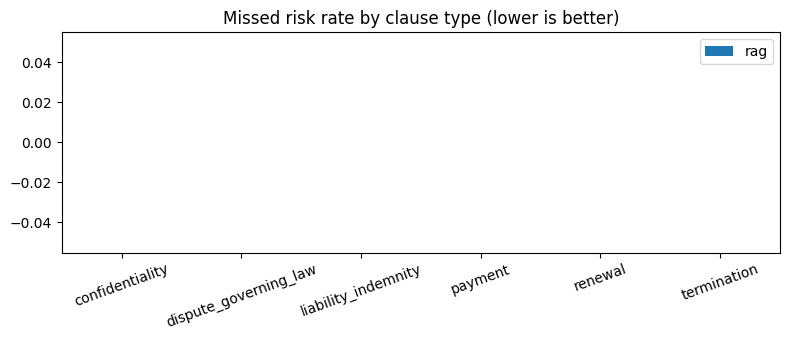

In [22]:
headline = pd.DataFrame({c: t.loc["all"] for c, t in track_b_tables.items()}).T
for c in RUNS:
    s = pd.DataFrame(json.load(open(RUNS[c] / "summary.json"))["contracts"])
    headline.loc[c, "cost_usd"] = s.cost_usd.sum()
    headline.loc[c, "minutes"] = s.elapsed_s.sum() / 60
    headline.loc[c, "tool_calls"] = s.tool_calls.sum() if "tool_calls" in s else 0   # the baseline has no tools
display(save(headline.round(3), "headline"))

ax = pd.DataFrame({c: t.drop("all")[["false_alarm_rate", "missed_risk_rate"]].stack() for c, t in track_b_tables.items()}) \
       .unstack().loc[:, (slice(None), "missed_risk_rate")].droplevel(1, axis=1) \
       .plot.bar(figsize=(8, 3.5), title="Missed risk rate by clause type (lower is better)", rot=20)
ax.figure.tight_layout(); ax.figure.savefig(OUT / "missed_risk_by_family.png", dpi=150)

## 18. Graders: deterministic checks and an LLM judge

Two kinds of graders score every finding without a human:

* **Deterministic** (free, exact, run on all three conditions): is the output well formed, and does it follow the rules we can check in code?
* **LLM as a judge** (costs API calls): does the quoted evidence actually support the verdict under the rubric, and is the revision ask useful? A judge is only worth trusting if it agrees with people, so we check it against the gold labels and against our own Track C ratings.

In [32]:
VERDICTS, SEVERITIES = {"acceptable", "risky", "missing", "unclear"}, {"high", "medium", "low", "n/a"}


def deterministic_checks(df, plans=None):
    quoted = df.evidence_text.fillna("").str.strip().replace("NONE FOUND", "") != ""
    checks = pd.DataFrame({
        "valid_verdict": df.verdict.isin(VERDICTS),
        "valid_severity": df.severity.fillna("n/a").isin(SEVERITIES),
        "severity_matches_verdict": (df.verdict == "acceptable") == (df.severity.fillna("n/a") == "n/a"),
        "quote_found_in_contract": df.evidence_verified.astype(str).str.lower() == "true",
        "flag_has_a_quote": ~df.verdict.isin({"risky", "unclear"}) | quoted,
        "missing_has_search_record": (df.verdict != "missing") | df.notes.fillna("").str.contains("search", case=False),
    })
    out = checks.mean()
    if plans is not None:                 # revision plan sorted by rubric §7: severity, then verdict
        sev, ver = {"high": 0, "medium": 1, "low": 2}, {"risky": 0, "missing": 1, "unclear": 2}
        keys = [[(sev.get(i.get("severity"), 3), ver.get(i.get("verdict"), 3)) for i in items] for items in plans.values()]
        out["plan_in_rubric_order"] = sum(k == sorted(k) for k in keys) / max(len(keys), 1)
    return out


def load_plans(c):          # the baseline (04) writes no revision plan
    p = RUNS[c] / "revision_plans.json"
    return json.load(open(p)) if p.exists() else None


det = pd.DataFrame({c: deterministic_checks(pred[pred.condition == c], load_plans(c)) for c in RUNS}).round(2)
display(save(det, "deterministic_checks"))

,rag
valid_verdict,1.00
valid_severity,1.00
severity_matches_verdict,1.00
quote_found_in_contract,0.92
flag_has_a_quote,1.00
missing_has_search_record,1.00


### LLM as a judge

The judge sees the rubric for the family, the agent's verdict, its quote and its notes, and answers two questions on a 1–3 scale. It never sees the gold label. Set `JUDGE_MODEL` to a stronger model than the agent's if the course credit allows, so the judge is not grading its own mistakes. `MAX_JUDGE_CALLS` caps the cost.

In [33]:
import re
from openai import OpenAI

JUDGE_MODEL = "@30875-fall26-openai/gpt-5-nano"     # a stronger model is better if available
MAX_JUDGE_CALLS = 300
judge_client = OpenAI(api_key=api_key, base_url="https://api.portkey.ai/v1") if api_key else None

rubric_text = (DATA_DIR / "rubric_v1.md").read_text()
RUBRIC_BY_FAMILY = {f: re.search(rf"^## \d+\. {f}\n(.*?)(?=^## )", rubric_text, re.S | re.M).group(1) for f in FAMILIES}

FINDING_JUDGE = """You grade a contract reviewer's finding for a small-business customer, using this rubric:

{rubric}

Finding: family={family}, verdict={verdict}, severity={severity}
Quoted evidence ({section}): "{quote}"
Reviewer's notes: {notes}

Answer in JSON only: {{"supported": 1-3, "answers_rubric": 1-3, "reason": "one sentence"}}
supported: 3 = the quote clearly justifies this verdict and severity under the rubric, 2 = partly, 1 = it does not (wrong verdict, wrong severity, or the quote is about something else).
answers_rubric: 3 = the notes address the rubric sub-criterion that decides this family, 1 = they do not."""

PLAN_JUDGE = """A small-business customer will send this ask to a vendor about a contract clause.
Finding: {family} ({verdict}, {severity}). Clause: "{quote}"
Ask: {ask}
Fallback: {fallback}

Answer in JSON only: {{"grounded": 1-3, "specific": 1-3, "actionable": 1-3, "reason": "one sentence"}}
grounded: follows from the clause. specific: says exactly what to change (a number, a period, a cap). actionable: could be sent as is."""

calls = 0
SCORES = ("supported", "answers_rubric", "grounded", "specific", "actionable")


def one_score(v):
    """A small model does not always return a bare number: it may send [3], "3" or "3/3".
    Keep an integer 1-3, otherwise drop the field so it reads as "not scored" instead of
    poisoning the column (a list in a numeric column makes .mean() raise)."""
    if isinstance(v, (list, tuple)):
        v = v[0] if v else None
    if isinstance(v, str):
        v = v.strip().split("/")[0].strip()
    try:
        n = int(float(v))
    except (TypeError, ValueError):
        return None
    return n if 1 <= n <= 3 else None


def judge(prompt):
    global calls
    if judge_client is None or calls >= MAX_JUDGE_CALLS:
        return {}
    calls += 1
    reply = judge_client.chat.completions.create(model=JUDGE_MODEL, messages=[{"role": "user", "content": prompt}])
    text = reply.choices[0].message.content or ""
    try:
        d = json.loads(text[text.index("{"):text.rindex("}") + 1])
    except ValueError:
        return {}
    if not isinstance(d, dict):
        return {}
    out = {k: v for k, v in d.items() if k not in SCORES}
    for k in SCORES:                       # keep only scores that are usable numbers
        if k in d and (n := one_score(d[k])) is not None:
            out[k] = n
    return out


def judge_findings(df):
    out = []
    for r in df.itertuples():
        j = judge(FINDING_JUDGE.format(rubric=RUBRIC_BY_FAMILY[r.family], family=r.family, verdict=r.verdict,
                                       severity=r.severity, section=r.section_ref, quote=str(r.evidence_text)[:800],
                                       notes=str(r.notes)[:600]))
        out.append({"contract_id": r.contract_id, "family": r.family, **j})
    return pd.DataFrame(out).set_index(["contract_id", "family"])


JUDGED = {}
for c in RUNS:
    JUDGED[c] = judge_findings(pred[pred.condition == c]).join(gold.verdict.rename("gold")) \
        .join(pred[pred.condition == c].set_index(["contract_id", "family"]).verdict)
print(calls, "judge calls")

24 judge calls


Is the judge trustworthy? If it is, findings whose verdict matches gold should get high `supported` scores and wrong ones low. `judge_separates` is the mean score on right findings minus the mean on wrong ones (bigger is better; near 0 means the judge cannot tell them apart).

In [34]:
rows = {}
for c, j in JUDGED.items():
    if "supported" not in j:
        continue
    right = j.verdict == j.gold
    rows[c] = {"mean_supported": j.supported.mean(), "mean_answers_rubric": j.answers_rubric.mean(),
               "supported_when_right": j.supported[right].mean(), "supported_when_wrong": j.supported[~right].mean(),
               "judge_separates": j.supported[right].mean() - j.supported[~right].mean(),
               "judge_flags_wrong (score 1)": (j.supported[~right] == 1).mean()}
if rows:
    display(save(pd.DataFrame(rows).T.round(2), "llm_judge_findings"))

,mean_supported,mean_answers_rubric,supported_when_right,supported_when_wrong,judge_separates,judge_flags_wrong (score 1)
rag,2.17,2.67,2.5,2.1,0.4,0.35


## 19. Track C: are the recommendations useful?

Same grader as `05`, same three criteria rated 1–3 (`grounded`, `specific`, `actionable`), and the same `PLAN_JUDGE` prompt — only the source differs by condition, because the two systems emit a recommendation in different shapes:

* the **agent** writes a prioritized `revision_plans.json` with an `ask` and a `fallback` per finding;
* the **baseline** has no aggregation step, so `04` writes one `recommendation` per flagged row and `plan_items` builds the same record from it, with an empty `fallback`.

**Your ratings survive a re-run.** The model is not deterministic, so every run rewords the asks. Two things protect the ratings:

1. Each item is keyed by `condition + contract_id + family`, never by its position in the list. A family never moves, so a rating always lands on the item it was written for. (The `id` column is kept only to show the rubric §7 order.)
2. Each item carries an `ask_hash`, a fingerprint of the ask's wording. If a re-run rewords an ask, the key still matches but the hash does not, and the next cell tells you how many of your ratings were written against older wording.

**The LLM judge is cached** to `scores/llm_judge_plan.csv` and only scores items it has not seen (same key *and* same wording). So the judge's numbers stay fixed once produced, a re-run costs nothing for unchanged items, and the figure in the report does not drift.

**Freeze the run you rate.** Once you have the run you intend to report, keep `runs/baseline_<split>/` and `scores/llm_judge_plan.csv` — download the zip from §21 and commit it. Rate against that, and do not re-run the baseline afterwards. The ratings belong to one run; the code tells you when they have drifted, but it cannot re-rate for you.

In [35]:
import hashlib

CRITERIA = ["grounded", "specific", "actionable"]
RATINGS_KEY = ["condition", "contract_id", "family"]   # stable across runs; the §7 `id` is not


def ask_id(text):
    """Fingerprint of an ask's wording, so a re-run can say which items actually changed."""
    return hashlib.sha1(" ".join(str(text or "").split()).lower().encode()).hexdigest()[:8]


def plan_items(c):
    """Rateable recommendations for one condition, in one shape.
    The agent writes revision_plans.json; the baseline writes one recommendation per flagged row."""
    COLS = ["condition", "contract_id", "family", "id", "severity", "evidence", "ask", "fallback", "ask_hash"]
    p = RUNS[c] / "revision_plans.json"
    if p.exists():
        df = pd.DataFrame([{"contract_id": cid, "id": it["id"], "family": it["family"],
                            "severity": it.get("severity", ""),
                            "evidence": str(it.get("evidence_text", ""))[:300],
                            "ask": it.get("ask", ""), "fallback": it.get("fallback", "")}
                           for cid, items in json.load(open(p)).items() for it in items])
    else:
        d = pred[(pred.condition == c) & (pred.verdict != "acceptable")].copy()
        if "recommendation" not in d:               # no plan and no recommendation: nothing to rate
            return pd.DataFrame(columns=COLS)
        d = d[d.recommendation.fillna("").str.strip() != ""]
        d["fam_order"] = d.family.map({f: i for i, f in enumerate(FAMILIES)})
        d = d.sort_values(["contract_id", "fam_order"])
        d["id"] = d.groupby("contract_id").cumcount() + 1
        df = pd.DataFrame({"contract_id": d.contract_id, "id": d.id, "family": d.family,
                           "severity": d.severity, "evidence": d.evidence_text.fillna("").str[:300],
                           "ask": d.recommendation.fillna(""), "fallback": ""}).reset_index(drop=True)
    if not len(df):
        return pd.DataFrame(columns=COLS)
    df["condition"], df["ask_hash"] = c, df.ask.map(ask_id)
    return df[COLS]


SHEET = {c: plan_items(c) for c in RUNS}
template = pd.concat(SHEET.values(), ignore_index=True)
for k in CRITERIA:
    template[k] = ""
template.to_csv(OUT / "ratings_template.csv", index=False)
for c, s in SHEET.items():
    print(f"{c}: {len(s)} items to rate")
print("hand-rating sheet ->", OUT / "ratings_template.csv")

# --- the judge, cached: only score an item whose key AND wording we have not judged before ---
JUDGE_CACHE = OUT / "llm_judge_plan.csv"
KEYH = RATINGS_KEY + ["ask_hash"]
cached = pd.read_csv(JUDGE_CACHE) if JUDGE_CACHE.exists() else pd.DataFrame(columns=KEYH + CRITERIA)
for k in CRITERIA:                          # a cache written before judge() was hardened may hold "[3]"
    if k in cached:
        cached[k] = cached[k].map(one_score)
cached = cached.dropna(subset=[k for k in CRITERIA if k in cached], how="all")
seen = set(map(tuple, cached[KEYH].astype(str).values)) if len(cached) else set()
todo = [r for s in SHEET.values() for r in s.itertuples()
        if (str(r.condition), str(r.contract_id), str(r.family), str(r.ask_hash)) not in seen]
print(f"judge: {len(cached)} cached, {len(todo)} to score")

fresh = pd.DataFrame([{"condition": r.condition, "contract_id": r.contract_id, "family": r.family,
                       "ask_hash": r.ask_hash,
                       **judge(PLAN_JUDGE.format(family=r.family, verdict="", severity=r.severity,
                                                 quote=r.evidence, ask=r.ask, fallback=r.fallback))}
                      for r in todo])
plan_judge = pd.concat([cached, fresh], ignore_index=True) if len(fresh) else cached
plan_judge = plan_judge.drop_duplicates(KEYH, keep="last")
for k in CRITERIA:                          # keep the score columns numeric, never object
    if k in plan_judge:
        plan_judge[k] = pd.to_numeric(plan_judge[k], errors="coerce")
if len(plan_judge) and "grounded" in plan_judge:
    plan_judge.to_csv(JUDGE_CACHE, index=False)     # keep it: a re-judge costs money and drifts
    display(plan_judge.groupby("condition")[CRITERIA].mean().round(2))
print(calls, "judge calls this session")

rag: 24 items to rate
hand-rating sheet -> scores/ratings_template.csv
judge: 24 cached, 0 to score


,grounded,specific,actionable
condition,,,
rag,2.5,2.76,2.96


24 judge calls this session


In [36]:
def read_ratings(p):
    d = pd.read_csv(p)
    if "condition" not in d:                        # a hand sheet covering one condition only
        d["condition"] = next(iter(RUNS))
    for k in CRITERIA:
        d[k] = pd.to_numeric(d.get(k), errors="coerce")
    return d


rated = {p.stem.split("_", 1)[1]: read_ratings(p) for p in sorted(Path(".").glob("ratings_*.csv"))
         if p.stem != "ratings_template"}
if len(plan_judge) and "grounded" in plan_judge:
    rated["llm_judge"] = plan_judge

now = template.set_index(RATINGS_KEY).ask_hash.astype(str).rename("now").reset_index()


def aligned(d, who):
    """One rating per item, for items that still exist in this run.
    Where a rater has both an old and a current wording, the current one wins; the rest are reported."""
    m = d.merge(now, on=RATINGS_KEY, how="left")
    lost = int(m.now.isna().sum())
    m = m[m.now.notna()].dropna(subset=CRITERIA, how="all").copy()
    m["current"] = m.ask_hash.astype(str) == m.now if "ask_hash" in m else True
    m = m.sort_values("current").drop_duplicates(RATINGS_KEY, keep="last")   # keep the current wording
    stale = int((~m.current).sum())
    note = f"{len(m)}/{len(now)} items rated"
    if stale:
        note += f"; {stale} only rated against an older wording (re-rate those)"
    if lost:
        note += f"; {lost} ratings match no item in this run"
    print(f"  {who}: {note}")
    return m.set_index(RATINGS_KEY)[CRITERIA]


use = {w: a for w, a in ((w, aligned(d, w)) for w, d in rated.items()) if len(a)}

if use:
    display(save(pd.concat({who: a.groupby(level="condition").mean().round(2) for who, a in use.items()},
                           names=["rater"]), "track_c_means"))
    names = list(use)
    pairs = {}
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            both = use[a].merge(use[b], on=RATINGS_KEY, suffixes=("_a", "_b")).dropna()
            if len(both) > 1:
                pairs[f"{a} vs {b}"] = {k: cohen_kappa_score(both[k + "_a"].astype(int),
                                                             both[k + "_b"].astype(int),
                                                             weights="quadratic") for k in CRITERIA}
    if pairs:
        display(save(pd.DataFrame(pairs).T.round(2), "track_c_agreement"))   # judge vs human = trust the judge?
else:
    print("no usable ratings yet. Fill in", OUT / "ratings_template.csv",
          "and put each finished copy next to this notebook as ratings_<name>.csv;",
          "the LLM judge appears here too once it has run with an API key.")

  llm_judge: 24/24 items rated


,,grounded,specific,actionable
rater,condition,,,
llm_judge,rag,2.5,2.76,2.96


## 20. Retrieval check: is the baseline reading the right passages?

Identical to `05` §24, and it applies here for the same reason: the baseline and the agent's pre-pass retrieve the same way, so this chooses the retrieval settings for both. No model calls (only embeddings for `dense` and `hybrid`). For every contract × family, the "relevant" text is where the gold quotes and CUAD's highlights are. For each query strategy, retrieval mode and chunk size we measure, with the same `k` the baseline uses:

* **hit@k**: at least one retrieved chunk overlaps a relevant passage
* **MRR**: 1 / rank of the first relevant chunk (higher = found earlier)
* **coverage**: share of the relevant passages the retrieved chunks touch (the model can only quote what it sees)

Query strategies: `name` (the family name), `keywords` (the rubric's keyword list, what the baseline uses), `multi` (one query per rubric sub-criterion, fused with reciprocal-rank fusion). Choose on **dev**, report **test**. This closes the proposal's §9 commitment to compare retrieval modes and chunking.

In [38]:
import pandas as pd

gold_lab = pd.read_excel(DATA_DIR / "labels_gold.xlsx")
cuad_rows = pd.read_csv(DATA_DIR / "cuad_gold_spans.csv")
meta = load_meta()


def relevant_spans(c, fam):
    g = gold_lab[(gold_lab.contract_id == c.cid) & (gold_lab.family == fam)]
    quotes = [q for k in ("evidence_text", "evidence_2") for q in g[k].dropna() if isinstance(q, str)]
    spans = [sp for sp in map(c.locate, quotes) if sp]
    rows = cuad_rows[(cuad_rows.contract_id == c.cid) & (cuad_rows.family == fam)]
    return spans + [(s, s + len(t)) for s, t in zip(rows.answer_start, rows.text)]


def sub_criteria(fam):
    return [v.strip("| \n").replace("|", " ") for k, v in RUBRIC.rules.items() if k.startswith(fam + ".") and v.startswith("| ")]


def retrieve(r, fam, strategy, mode, k):
    if strategy == "name":
        return [h["chunk"] for h in r.search(fam.replace("_", " "), mode, k)[1]]
    if strategy == "keywords":
        return [h["chunk"] for h in r.search(RUBRIC.family_keywords.get(fam, fam), mode, k)[1]]
    score = {}                                      # multi: one query per sub-criterion, reciprocal-rank fusion
    for q in [RUBRIC.family_keywords.get(fam, fam)] + sub_criteria(fam):
        for rank, h in enumerate(r.search(q, mode, 2 * k)[1]):
            score[h["chunk"]] = score.get(h["chunk"], 0) + 1 / (60 + rank)
    return sorted(score, key=score.get, reverse=True)[:k]


def retrieval_eval(strategies=("name", "keywords", "multi"), modes=("sparse", "dense", "hybrid"),
                   chunkings=((110, 30), (200, 50)), k=TOP_K):
    rows = []
    for cid in sorted(meta):
        for words, overlap in chunkings:
            c = Contract.load(DATA_DIR / "contracts" / f"{cid}.txt", meta[cid], chunk_words=words, overlap=overlap)
            r = Retriever(c, EMBEDDER)
            for fam in FAMILIES:
                spans = relevant_spans(c, fam)
                if not spans:
                    continue
                touches = lambda i, sp: c.chunks[i].start < sp[1] and sp[0] < c.chunks[i].end
                for mode in modes if EMBEDDER else ("sparse",):
                    for strategy in strategies:
                        top = retrieve(r, fam, strategy, mode, k)
                        first = next((n for n, i in enumerate(top) if any(touches(i, sp) for sp in spans)), None)
                        rows.append({"split": meta[cid]["split"], "family": fam, "chunks": f"{words}/{overlap}",
                                     "mode": mode, "query": strategy, "hit@k": first is not None,
                                     "mrr": 0 if first is None else 1 / (first + 1),
                                     "coverage": sum(any(touches(i, sp) for i in top) for sp in spans) / len(spans),
                                     "words_read": sum(len(c.chunks[i].text.split()) for i in top)})
    return pd.DataFrame(rows)


ret = retrieval_eval()
table = ret.groupby(["split", "chunks", "mode", "query"])[["hit@k", "mrr", "coverage", "words_read"]].mean().round(3)
table.to_csv(OUT / "retrieval_eval.csv")
display(table.loc["dev"].sort_values("coverage", ascending=False))
display(table.loc["test"])

hit@k    mrr  coverage  words_read
chunks mode   query                                       
110/30 hybrid multi     1.000  0.788     0.942     440.000
200/50 sparse multi     1.000  0.788     0.936     797.292
       hybrid multi     1.000  0.896     0.925     799.000
              keywords  1.000  0.910     0.894     796.292
110/30 hybrid keywords  1.000  0.910     0.887     440.000
200/50 sparse keywords  0.958  0.917     0.883     797.292
110/30 sparse multi     0.958  0.715     0.862     440.000
       dense  multi     1.000  0.854     0.859     440.000
200/50 dense  name      0.958  0.889     0.840     785.958
110/30 dense  name      0.958  0.812     0.840     440.000
       sparse keywords  0.958  0.847     0.819     440.000
       dense  keywords  0.958  0.837     0.814     440.000
200/50 hybrid name      0.958  0.778     0.805     796.292
       dense  keywords  0.917  0.806     0.801     789.583
              multi     0.958  0.774     0.795     794.292
110/30 hybrid name      0.958  0.767     0.770     440.000
200/50 sparse name      0.833  0.628     0.701     796.292
110/30 sparse name      0.792  0.597     0.604     440.000

hit@k    mrr  coverage  words_read
chunks mode   query                                       
110/30 dense  keywords  0.934  0.806     0.791     439.426
              multi     0.918  0.779     0.796     437.590
              name      0.885  0.809     0.748     435.656
       hybrid keywords  0.967  0.861     0.827     438.508
              multi     0.951  0.802     0.837     440.000
              name      0.836  0.713     0.680     438.508
       sparse keywords  0.902  0.766     0.785     436.443
              multi     0.852  0.689     0.703     439.426
              name      0.738  0.622     0.581     439.082
200/50 dense  keywords  0.902  0.719     0.795     784.000
              multi     0.934  0.769     0.843     792.541
              name      0.885  0.738     0.776     770.410
       hybrid keywords  0.967  0.846     0.858     790.410
              multi     0.951  0.786     0.847     795.967
              name      0.869  0.749     0.774     796.951
       sparse keywords  0.951  0.821     0.867     786.279
              multi     0.885  0.706     0.744     796.197
              name      0.787  0.652     0.684     797.836

## 21. Download everything

`runs/` holds the baseline run, `scores/` the tables and the chart.

In [39]:
print(sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    !zip -qr baseline_scores_{SPLIT}.zip runs scores
    files.download(f"baseline_scores_{SPLIT}.zip")

['deterministic_checks.csv', 'headline.csv', 'kappa_jenny_vs_kayla.csv', 'llm_judge_findings.csv', 'llm_judge_plan.csv', 'missed_risk_by_family.png', 'ratings_template.csv', 'retrieval_eval.csv', 'track_a_clause_detection.csv', 'track_b_verdicts.csv', 'track_c_means.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>